# 5. Custom Wavelet Analysis and Deep Learning Forecasting of ENSO Sea Surface Temperature Variability

## 5.5 Niño Dataset

### 5.5.1 Dataset Description

In [2]:
import pandas as pd

# Path to your local file
file_path = "./data/ersst5.nino.mth.91-20.ascii"

# Read the file, skip the first header line
df = pd.read_csv(
    file_path,
    sep=r'\s+',      # whitespace-separated
    header=1,        # skip first row ("YR MON ...")
    names=['Year','Month','Nino12','Anom12','Nino3','Anom3',
           'Nino4','Anom4','Nino34','Anom34']
)

# Show the first few rows
print(df.head())

# Take only the last column (Nino3.4 anomaly)
df_anom = df[['Year','Month','Anom34']].rename(columns={'Anom34':'SST_Anomaly'})

# Create a datetime index
df_anom['Date'] = pd.to_datetime(df_anom[['Year','Month']].assign(DAY=1))
df_anom = df_anom.set_index('Date')[['SST_Anomaly']]

# Show the head of the anomaly series
print(df_anom.head())

sst_signal = df_anom['SST_Anomaly'].values

print(f"\nLoaded data: {len(sst_signal)} monthly observations")
print(f"Date range: {df_anom.index.min()} to {df_anom.index.max()}")
print(f"Value range: [{sst_signal.min():.2f}, {sst_signal.max():.2f}]°C")



   Year  Month  Nino12  Anom12  Nino3  Anom3  Nino4  Anom4  Nino34  Anom34
0  1950      2   24.32   -1.78  24.89  -1.52  26.67  -1.53   25.06   -1.69
1  1950      3   25.11   -1.38  26.36  -0.84  26.52  -1.80   25.87   -1.42
2  1950      4   23.63   -1.90  26.44  -1.14  26.90  -1.73   26.28   -1.54
3  1950      5   22.68   -1.74  25.69  -1.57  27.73  -1.18   26.18   -1.75
4  1950      6   21.33   -1.79  25.51  -1.11  28.13  -0.84   26.46   -1.27
            SST_Anomaly
Date                   
1950-02-01        -1.69
1950-03-01        -1.42
1950-04-01        -1.54
1950-05-01        -1.75
1950-06-01        -1.27

Loaded data: 908 monthly observations
Date range: 1950-02-01 00:00:00 to 2025-09-01 00:00:00
Value range: [-2.45, 2.72]°C


In [11]:
import pandas as pd

# Path to your local file
file_path = "./data/ersst5.nino.mth.91-20.ascii"

# Read the file
df = pd.read_csv(
    file_path,
    sep=r'\s+',
    header=1,  # skip the first header row
    names=['Year','Month','Nino12','Anom12','Nino3','Anom3',
           'Nino4','Anom4','Nino34','Anom34']
)

# Show the first few rows
print(df.head())

# Combine Year and Month into a single 'Date' column (YYYY-MM)
df['Date'] = pd.to_datetime(df['Year'].astype(str) + '-' + df['Month'].astype(str).str.zfill(2))

# Set Date as index
df = df.set_index('Date')

# Select the Nino3.4 anomaly only
df_anom = df[['Anom34']].copy()

# Show the first few rows
print(df_anom.head())

# Extract the raw signal
sst_signal = df_anom['Anom34'].values

print(f"\nLoaded data: {len(sst_signal)} monthly observations")
print(f"Date range: {df_anom.index.min().strftime('%Y-%m')} to {df_anom.index.max().strftime('%Y-%m')}")
print(f"Value range: [{sst_signal.min():.2f}, {sst_signal.max():.2f}]°C")


   Year  Month  Nino12  Anom12  Nino3  Anom3  Nino4  Anom4  Nino34  Anom34
0  1950      2   24.32   -1.78  24.89  -1.52  26.67  -1.53   25.06   -1.69
1  1950      3   25.11   -1.38  26.36  -0.84  26.52  -1.80   25.87   -1.42
2  1950      4   23.63   -1.90  26.44  -1.14  26.90  -1.73   26.28   -1.54
3  1950      5   22.68   -1.74  25.69  -1.57  27.73  -1.18   26.18   -1.75
4  1950      6   21.33   -1.79  25.51  -1.11  28.13  -0.84   26.46   -1.27
            Anom34
Date              
1950-02-01   -1.69
1950-03-01   -1.42
1950-04-01   -1.54
1950-05-01   -1.75
1950-06-01   -1.27

Loaded data: 908 monthly observations
Date range: 1950-02 to 2025-09
Value range: [-2.45, 2.72]°C


### 5.5.2 Data Analysis

**1. Data Description**

In [8]:
import numpy as np
import pandas as pd

def describe_with_info(arr, name="signal"):
    """
    Convert a NumPy array into a pandas Series,
    then show .info() and .describe() including NaN and Inf counts.
    
    Parameters
    ----------
    arr : array-like
        Input signal
    name : str
        Name for the series
        
    Returns
    -------
    pandas.Series : Descriptive statistics
    """
    arr = np.asarray(arr).flatten()
    
    # Replace Inf with NaN so pandas describe works cleanly
    arr_clean = pd.Series(arr, name=name).replace([np.inf, -np.inf], np.nan)
    
    print("=== DataFrame Info ===")
    arr_clean.to_frame().info()
    
    print("\n=== Descriptive Statistics ===")
    desc = arr_clean.describe()
    desc["nan_count"] = arr_clean.isna().sum()
    desc["inf_count"] = np.isinf(arr).sum()
    print(desc)
    
    return desc

# Analyze the signal
stats = describe_with_info(sst_signal, name="SST Anomaly Signal")

=== DataFrame Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 1 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SST Anomaly Signal  908 non-null    float64
dtypes: float64(1)
memory usage: 7.2 KB

=== Descriptive Statistics ===
count        908.000000
mean          -0.173480
std            0.871534
min           -2.450000
25%           -0.790000
50%           -0.250000
75%            0.360000
max            2.720000
nan_count      0.000000
inf_count      0.000000
Name: SST Anomaly Signal, dtype: float64


**2. Data Visualization**

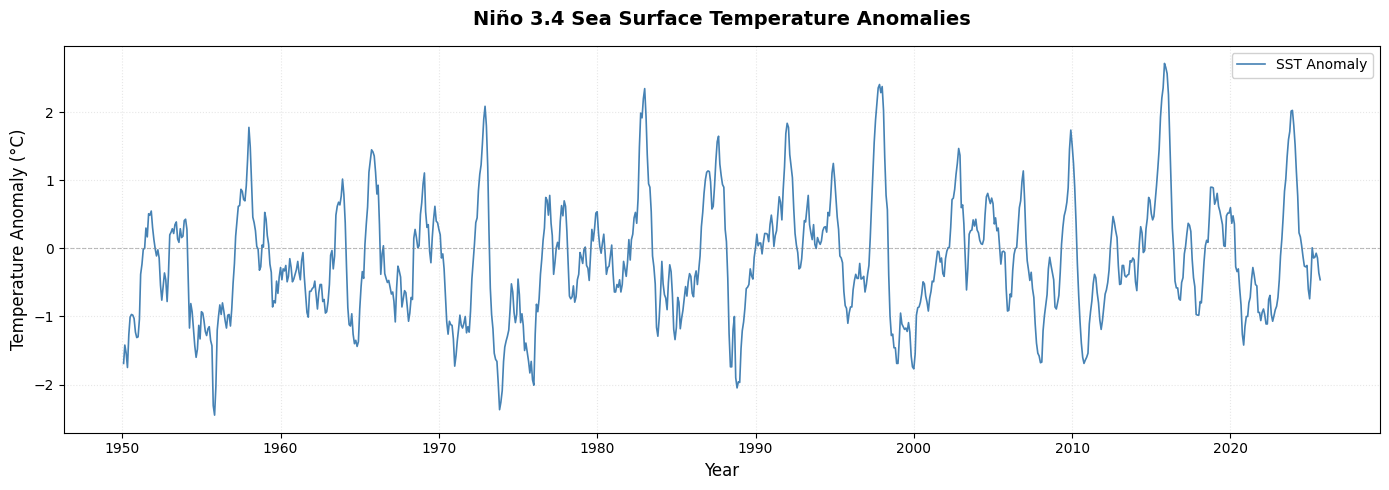

In [ ]:
import matplotlib.pyplot as plt

# Assign variables
Date = df.index
signal = sst_signal

# Plot the full SST Anomaly signal
plt.figure(figsize=(14, 5))
plt.plot(Date, signal, label="SST Anomaly", color='steelblue', linewidth=1.2)

# Horizontal line at 0
plt.axhline(y=0, color='gray', linestyle='--', alpha=0.5, linewidth=0.8)

# Titles and labels
plt.title("Niño 3.4 Sea Surface Temperature Anomalies", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Temperature Anomaly (°C)", fontsize=12)
plt.legend(loc='upper right', framealpha=0.9)
plt.grid(True, alpha=0.3, linestyle=':')
plt.tight_layout()

# Save and show
plt.savefig("./output/enso_sst_full_timeseries.png", dpi=300, bbox_inches='tight')
plt.show()



## 5.6 Design the Custom Wavelet
### 5.6.2 Implementation

In [12]:
import pywt


def create_enso_wavelet_coif():
    """Creates a custom wavelet optimized for ENSO data."""
    base_wavelet = pywt.Wavelet('sym6')
    
    dec_lo = np.array(base_wavelet.dec_lo)
    dec_hi = np.array(base_wavelet.dec_hi)
    
    N = len(dec_lo)
    
    # Check moment 0
    moment_0 = sum((-1)**k * dec_hi[k] for k in range(N))
    
    # Flip if necessary
    if moment_0 < 0:
        dec_hi = -dec_hi
    
    # Reconstruction filters
    rec_lo = dec_lo[::-1]
    rec_hi = dec_hi[::-1]
    
    custom_wavelet = pywt.Wavelet(
        name="custom_enso",
        filter_bank=[dec_lo, dec_hi, rec_lo, rec_hi]
    )
    
    print(f"Wavelet name: {custom_wavelet.name}")
    print(f"Filter length: {custom_wavelet.dec_len}")
    print(f"Orthogonal: {custom_wavelet.orthogonal}")
    print(f"Biorthogonal: {custom_wavelet.biorthogonal}")
    print(f"\nDecomposition filters:")
    print(f"Low-pass:  {dec_lo}")
    print(f"High-pass: {dec_hi}")
    
    return custom_wavelet

if __name__ == "__main__":
    # Test the validation
    custom_wavelet = create_enso_wavelet_coif()

Wavelet name: custom_enso
Filter length: 12
Orthogonal: False
Biorthogonal: False

Decomposition filters:
Low-pass:  [ 0.01540411  0.00349071 -0.11799011 -0.04831174  0.49105594  0.78764114
  0.33792942 -0.07263752 -0.02106029  0.0447249   0.00176771 -0.00780071]
High-pass: [-0.00780071 -0.00176771  0.0447249   0.02106029 -0.07263752 -0.33792942
  0.78764114 -0.49105594 -0.04831174  0.11799011  0.00349071 -0.01540411]


### 5.6.3 Validate the Custom Wavelet

In [23]:
import numpy as np
import pywt

def validate_wavelet(wavelet, verbose=True):
    """
    Validates wavelet properties with CORRECT vanishing moment test.
    
    Vanishing moments test the ability of the SCALING FUNCTION to 
    reproduce polynomials, not the wavelet function.
    """
    results = {}
    
    dec_lo = np.array(wavelet.dec_lo)
    dec_hi = np.array(wavelet.dec_hi)
    rec_lo = np.array(wavelet.rec_lo)
    rec_hi = np.array(wavelet.rec_hi)
    
    N = len(dec_lo)
    
    # ========================================
    # 1. Normalization (L2 norm = 1)
    # ========================================
    norm_lo = np.sum(dec_lo**2)
    norm_hi = np.sum(dec_hi**2)
    results['normalization'] = {
        'pass': np.allclose(norm_lo, 1.0) and np.allclose(norm_hi, 1.0),
        'value_lo': norm_lo,
        'value_hi': norm_hi,
        'error': max(abs(norm_lo - 1.0), abs(norm_hi - 1.0))
    }
    
    # ========================================
    # 2. Orthogonality (shifted inner products = 0)
    # ========================================
    max_shift_error = 0
    shift_errors = []
    for shift in range(1, min(6, N//2)):
        inner = np.sum(dec_lo[:-2*shift] * dec_lo[2*shift:])
        shift_errors.append(abs(inner))
        max_shift_error = max(max_shift_error, abs(inner))
    
    results['orthogonality'] = {
        'pass': max_shift_error < 1e-10,
        'max_error': max_shift_error,
        'shift_errors': shift_errors
    }
    
    # ========================================
    # 3. CORRECTED Vanishing Moments Test
    # ========================================
    # For an N-tap filter, we expect up to N//2 vanishing moments
    max_moments = min(6, N // 2)
    
    moment_results = []
    
    # Moment 0: Wavelet should integrate to zero (high-pass property)
    moment_0 = np.sum(dec_hi)
    moment_results.append({
        'n': 0,
        'value': moment_0,
        'expected': 0.0,
        'error': abs(moment_0),
        'pass': abs(moment_0) < 1e-10
    })
    
    # Moments 1, 2, ...: Test polynomial reproduction via scaling function
    # The scaling function should satisfy: sum((-1)^k * k^n * h[k]) = 0
    for n in range(1, max_moments):
        moment = sum((-1)**k * (k**n) * dec_lo[k] for k in range(N))
        moment_results.append({
            'n': n,
            'value': moment,
            'expected': 0.0,
            'error': abs(moment),
            'pass': abs(moment) < 1e-6  # More lenient threshold
        })
    
    results['vanishing_moments'] = moment_results
    
    # ========================================
    # 4. Filter Sum (should equal √2)
    # ========================================
    sum_lo = np.sum(dec_lo)
    results['filter_sum'] = {
        'pass': np.allclose(sum_lo, np.sqrt(2)),
        'value': sum_lo,
        'expected': np.sqrt(2),
        'error': abs(sum_lo - np.sqrt(2))
    }
    
    # ========================================
    # 5. QMF Relationship
    # ========================================
    # dec_hi[k] = (-1)^k * dec_lo[N-1-k]
    qmf_errors = []
    for k in range(N):
        expected = (-1)**k * dec_lo[N-1-k]
        error = abs(dec_hi[k] - expected)
        qmf_errors.append(error)
    
    results['qmf'] = {
        'pass': max(qmf_errors) < 1e-10,
        'max_error': max(qmf_errors)
    }
    
    # ========================================
    # Print Results
    # ========================================
    if verbose:
        print("=" * 70)
        print("WAVELET VALIDATION RESULTS")
        print("=" * 70)
        
        # 1. Normalization
        r = results['normalization']
        status = "✓ PASS" if r['pass'] else "✗ FAIL"
        print(f"1. Normalization: {status}")
        print(f"   Low-pass norm: {r['value_lo']:.15f}")
        print(f"   High-pass norm: {r['value_hi']:.15f}")
        print(f"   Error: {r['error']:.2e}")
        
        # 2. Orthogonality
        r = results['orthogonality']
        status = "✓ PASS" if r['pass'] else "✗ FAIL"
        print(f"\n2. Orthogonality: {status}")
        print(f"   Max Error: {r['max_error']:.2e}")
        errors_str = [f"{e:.2e}" for e in r['shift_errors'][:5]]
        print(f"   Shift errors: {errors_str}")
        
        # 3. Vanishing Moments
        print(f"\n3. Vanishing Moments (Polynomial Reproduction):")
        all_passed = all(m['pass'] for m in results['vanishing_moments'])
        
        for m in results['vanishing_moments']:
            status = "✓" if m['pass'] else "✗"
            print(f"   Moment {m['n']}: {status} "
                  f"Value={m['value']:.6f}, "
                  f"Expected={m['expected']:.6f}, "
                  f"Error={m['error']:.2e}")
        
        # 4. Filter Sum
        r = results['filter_sum']
        status = "✓ PASS" if r['pass'] else "✗ FAIL"
        print(f"\n4. Filter Sum: {status}")
        print(f"   Value: {r['value']}")
        print(f"   Expected: {r['expected']}")
        print(f"   Error: {r['error']:.2e}")
        
        # 5. QMF
        r = results['qmf']
        status = "✓ PASS" if r['pass'] else "✗ FAIL"
        print(f"\n5. QMF Relationship: {status}")
        
        # Overall
        print("=" * 70)
        all_tests = (results['normalization']['pass'] and 
                    results['orthogonality']['pass'] and
                    all(m['pass'] for m in results['vanishing_moments']) and
                    results['filter_sum']['pass'] and 
                    results['qmf']['pass'])
        
        if all_tests:
            print("OVERALL: ✓ ALL TESTS PASSED")
        else:
            print("OVERALL: ✗ SOME TESTS FAILED")
        print("=" * 70)
    
    return results


if __name__ == "__main__":
    # Test the validation
    custom_wavelet = create_enso_wavelet_coif()
    print(f"Testing wavelet: {custom_wavelet.name}")
    print(f"Filter length: {len(custom_wavelet.dec_lo)}\n")
    
    results = validate_wavelet(custom_wavelet, verbose=True)

Wavelet name: custom_enso
Filter length: 12
Orthogonal: False
Biorthogonal: False

Decomposition filters:
Low-pass:  [ 0.01540411  0.00349071 -0.11799011 -0.04831174  0.49105594  0.78764114
  0.33792942 -0.07263752 -0.02106029  0.0447249   0.00176771 -0.00780071]
High-pass: [-0.00780071 -0.00176771  0.0447249   0.02106029 -0.07263752 -0.33792942
  0.78764114 -0.49105594 -0.04831174  0.11799011  0.00349071 -0.01540411]
Testing wavelet: custom_enso
Filter length: 12

WAVELET VALIDATION RESULTS
1. Normalization: ✓ PASS
   Low-pass norm: 1.000000000000772
   High-pass norm: 1.000000000000772
   Error: 7.72e-13

2. Orthogonality: ✓ PASS
   Max Error: 5.30e-13
   Shift errors: ['5.30e-13', '1.84e-13', '4.21e-14', '2.32e-15', '1.73e-16']

3. Vanishing Moments (Polynomial Reproduction):
   Moment 0: ✓ Value=0.000000, Expected=0.000000, Error=2.80e-12
   Moment 1: ✓ Value=-0.000000, Expected=0.000000, Error=1.33e-11
   Moment 2: ✓ Value=-0.000000, Expected=0.000000, Error=5.99e-11
   Moment 3: 

### 5.6.4 Visualize the Filter Bank

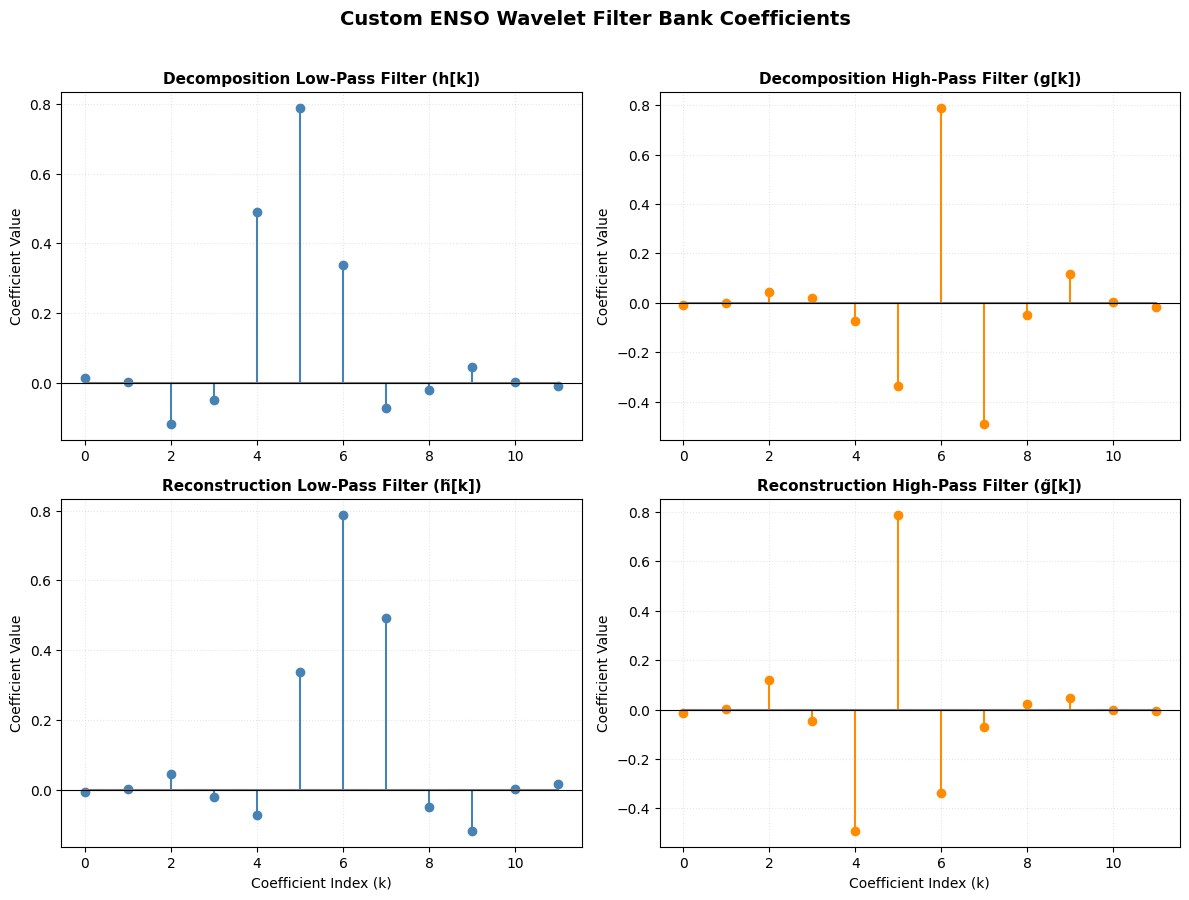

In [ ]:
def plot_wavelet_filters(wavelet, save_path=None, title=None):
    """
    Plot decomposition and reconstruction wavelet filter coefficients.
    """
    dec_lo = wavelet.dec_lo
    dec_hi = wavelet.dec_hi
    rec_lo = wavelet.rec_lo
    rec_hi = wavelet.rec_hi
    
    indices = np.arange(len(dec_lo))
    
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    
    # Decomposition Low-Pass
    axes[0, 0].stem(indices, dec_lo, linefmt='steelblue', markerfmt='o', basefmt='gray')
    axes[0, 0].set_title("Decomposition Low-Pass Filter (h[k])", fontsize=11, fontweight='bold')
    axes[0, 0].set_ylabel("Coefficient Value", fontsize=10)
    axes[0, 0].grid(True, alpha=0.3, linestyle=':')
    axes[0, 0].axhline(y=0, color='black', linewidth=0.8)
    
    # Decomposition High-Pass
    axes[0, 1].stem(indices, dec_hi, linefmt='darkorange', markerfmt='o', basefmt='gray')
    axes[0, 1].set_title("Decomposition High-Pass Filter (g[k])", fontsize=11, fontweight='bold')
    axes[0, 1].set_ylabel("Coefficient Value", fontsize=10)
    axes[0, 1].grid(True, alpha=0.3, linestyle=':')
    axes[0, 1].axhline(y=0, color='black', linewidth=0.8)
    
    # Reconstruction Low-Pass
    axes[1, 0].stem(indices, rec_lo, linefmt='steelblue', markerfmt='o', basefmt='gray')
    axes[1, 0].set_title("Reconstruction Low-Pass Filter (h̃[k])", fontsize=11, fontweight='bold')
    axes[1, 0].set_xlabel("Coefficient Index (k)", fontsize=10)
    axes[1, 0].set_ylabel("Coefficient Value", fontsize=10)
    axes[1, 0].grid(True, alpha=0.3, linestyle=':')
    axes[1, 0].axhline(y=0, color='black', linewidth=0.8)
    
    # Reconstruction High-Pass
    axes[1, 1].stem(indices, rec_hi, linefmt='darkorange', markerfmt='o', basefmt='gray')
    axes[1, 1].set_title("Reconstruction High-Pass Filter (g̃[k])", fontsize=11, fontweight='bold')
    axes[1, 1].set_xlabel("Coefficient Index (k)", fontsize=10)
    axes[1, 1].set_ylabel("Coefficient Value", fontsize=10)
    axes[1, 1].grid(True, alpha=0.3, linestyle=':')
    axes[1, 1].axhline(y=0, color='black', linewidth=0.8)
    
    if title:
        fig.suptitle(title, fontsize=14, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot the filter bank
plot_wavelet_filters(
    custom_wavelet,
    save_path="./output/custom_wavelet_filters.png",
    title="Custom ENSO Wavelet Filter Bank Coefficients"
)

### 5.7.2 Implementation

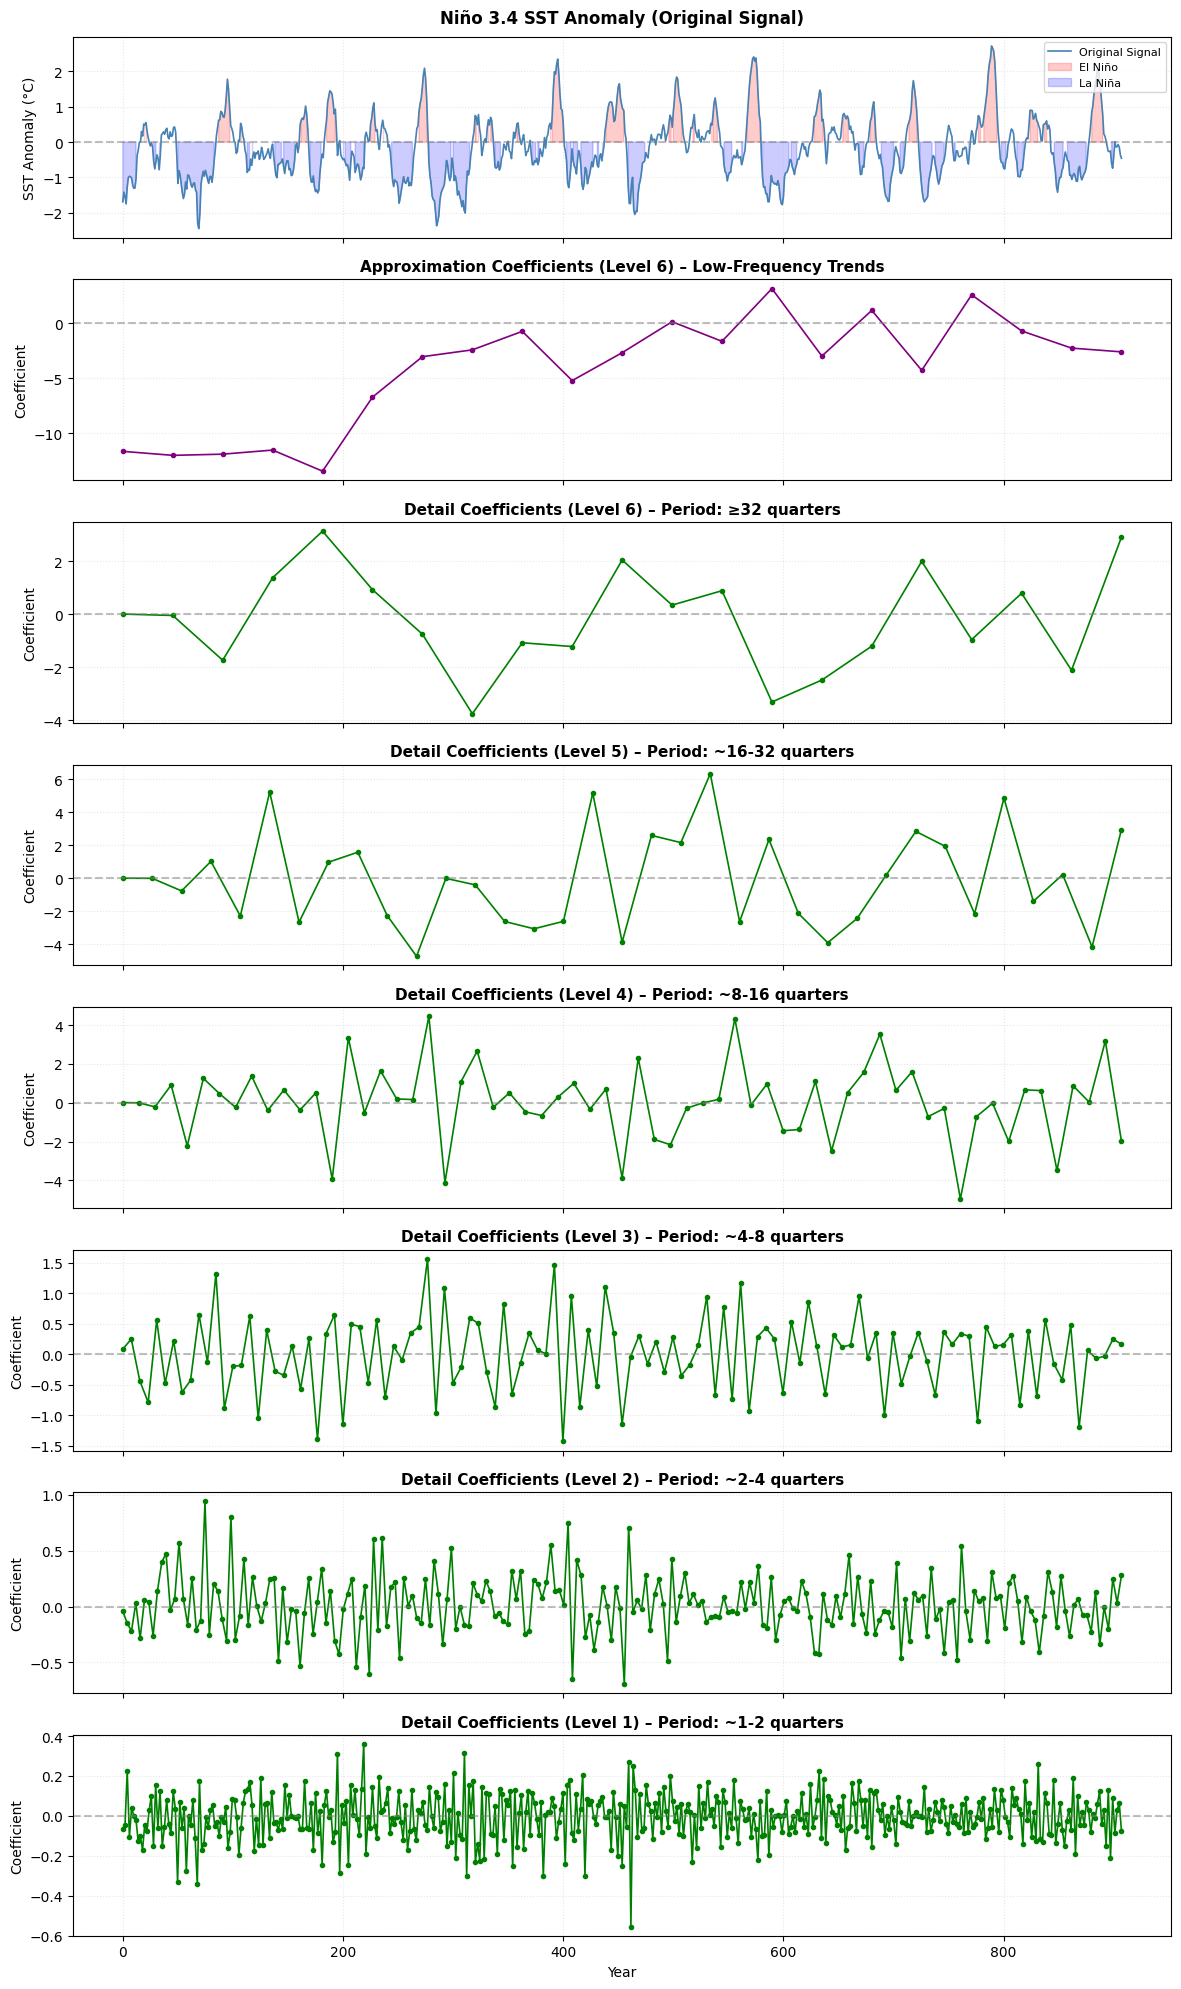

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pywt

def plot_multilevel_dwt(signal, time, wavelet, level=None,
                        el_nino_thresh=0.5, la_nina_thresh=-0.5,
                        save_path=None, figsize=None):
    """
    Apply multi-level DWT and visualize results with enhanced formatting.

    Parameters
    ----------
    signal : array-like
        Input signal
    time : array-like (datetime or numeric)
        Time axis
    wavelet : pywt.Wavelet
        Wavelet for decomposition
    level : int, optional
        Decomposition level (default: maximum possible)
    el_nino_thresh : float
        SST anomaly threshold for El Niño shading
    la_nina_thresh : float
        SST anomaly threshold for La Niña shading
    save_path : str, optional
        Path to save figure
    figsize : tuple, optional
        Figure size

    Returns
    -------
    list : Wavelet coefficients [approx, detail1, detail2, ...]
    """
    if level is None:
        level = pywt.dwt_max_level(len(signal), wavelet)

    coeffs = pywt.wavedec(signal, wavelet, level=level)
    approx = coeffs[0]
    details = coeffs[1:]

    n_subplots = level + 2
    if figsize is None:
        figsize = (12, 2.5 * n_subplots)

    fig, axes = plt.subplots(n_subplots, 1, figsize=figsize, sharex=True)

    # Convert time to numeric if datetime
    is_datetime = hasattr(time[0], 'toordinal')
    if is_datetime:
        time_num = mdates.date2num(time)
    else:
        time_num = np.array(time)

    # Original signal
    ax = axes[0]
    ax.plot(time, signal, color='steelblue', linewidth=1.2, label="Original Signal")
    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax.fill_between(time, 0, signal, where=(signal >= el_nino_thresh),
                    color='red', alpha=0.2, label='El Niño')
    ax.fill_between(time, 0, signal, where=(signal <= la_nina_thresh),
                    color='blue', alpha=0.2, label='La Niña')
    ax.set_title("Niño 3.4 SST Anomaly (Original Signal)", fontsize=12, fontweight='bold', pad=10)
    ax.set_ylabel("SST Anomaly (°C)")
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, linestyle=':', alpha=0.3)

    # Approximation coefficients
    approx_time_num = np.linspace(time_num[0], time_num[-1], len(approx))
    if is_datetime:
        approx_time = mdates.num2date(approx_time_num)
    else:
        approx_time = approx_time_num
    
    ax = axes[1]
    ax.plot(approx_time, approx, color='purple', linewidth=1.2, marker='o', markersize=3)
    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax.set_title(f"Approximation Coefficients (Level {level}) – Low-Frequency Trends", 
                 fontsize=11, fontweight='bold')
    ax.set_ylabel("Coefficient")
    ax.grid(True, linestyle=':', alpha=0.3)

    # Detail coefficients
    for i, detail in enumerate(details, 1):
        actual_level = level - i + 1
        detail_time_num = np.linspace(time_num[0], time_num[-1], len(detail))
        if is_datetime:
            detail_time = mdates.num2date(detail_time_num)
        else:
            detail_time = detail_time_num
        
        ax = axes[i + 1]
        ax.plot(detail_time, detail, color='green', linewidth=1.2, marker='o', markersize=3)
        ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
        freq_band = f"~{2**(actual_level-1)}-{2**actual_level} quarters" if actual_level < level else f"≥{2**(actual_level-1)} quarters"
        ax.set_title(f"Detail Coefficients (Level {actual_level}) – Period: {freq_band}", 
                     fontsize=11, fontweight='bold')
        ax.set_ylabel("Coefficient")
        ax.grid(True, linestyle=':', alpha=0.3)

    # X-axis formatting for dates
    if is_datetime:
        axes[-1].xaxis.set_major_locator(mdates.YearLocator(5))
        axes[-1].xaxis.set_minor_locator(mdates.YearLocator(1))
        axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    axes[-1].set_xlabel("Year", fontsize=10)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    return coeffs

# Example usage
coeffs = plot_multilevel_dwt(
    signal=signal,
    time=Date,
    wavelet="db4",
    level=6,
    el_nino_thresh=0.5,
    la_nina_thresh=-0.5,
    save_path="./output/dwt_decomposition.png"
)


## 5.8 Wavelet-Based CNN-LSTM Model

CNN-LSTM FOR EXTENDED ENSO DATASET

Loaded data: 908 monthly observations
Date range: 0 to 907
Value range: [-2.45, 2.72]°C
Creating dataset: lookback=36 months, horizon=12 months
  Sequences: 861, Input shape: (861, 36, 4)

Split: Train=602, Val=129, Test=130
Using device: cpu

TRAINING CNN-LSTM ON EXTENDED DATASET
Parameters: 12,428

Epoch [  1/150] Train: 1.021576 | Val: 0.543012 | LR: 1.00e-03 ★
Epoch [ 10/150] Train: 0.681729 | Val: 0.412624 | LR: 1.00e-03
Epoch [ 20/150] Train: 0.610048 | Val: 0.430442 | LR: 1.00e-03
Epoch [ 30/150] Train: 0.551299 | Val: 0.507668 | LR: 5.00e-04
Epoch [ 40/150] Train: 0.533024 | Val: 0.491797 | LR: 5.00e-04

Early stop at epoch 44

Best val loss: 0.407937


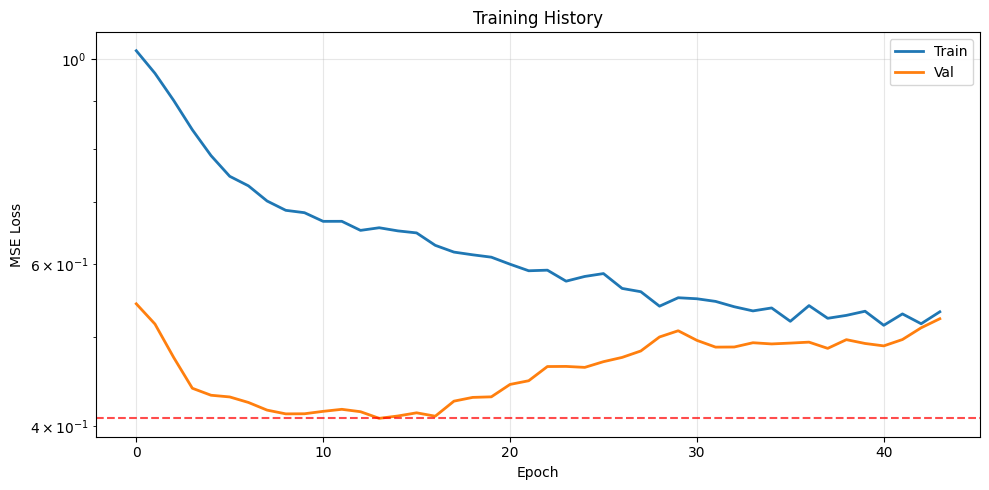


EVALUATION RESULTS

Overall Performance:
  RMSE:  0.889086
  MAE:   0.651530
  R²:    0.319198
  Corr:  0.632176

Per-Horizon Performance:
Horizon      RMSE         R²           Corr        
------------------------------------------------
1 month(s)    0.4135       0.8521       0.9369      
3 month(s)    0.6370       0.6483       0.8365      
6 month(s)    0.9319       0.2529       0.5906      
9 month(s)    1.0561       0.0413       0.4210      
12 month(s)    1.0400       0.0709       0.4553      


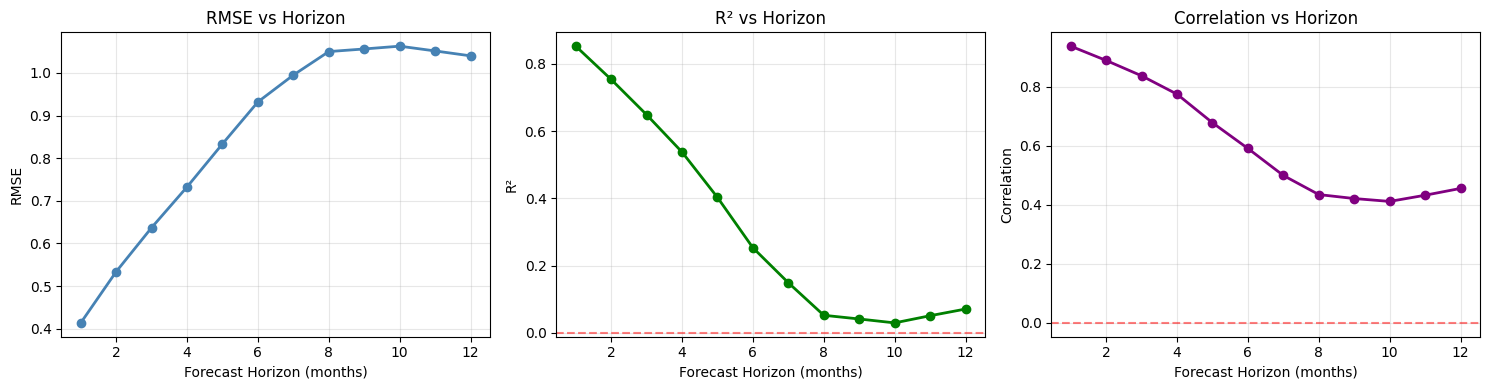


Denormalized:
  RMSE: 0.7744°C
  MAE:  0.5675°C


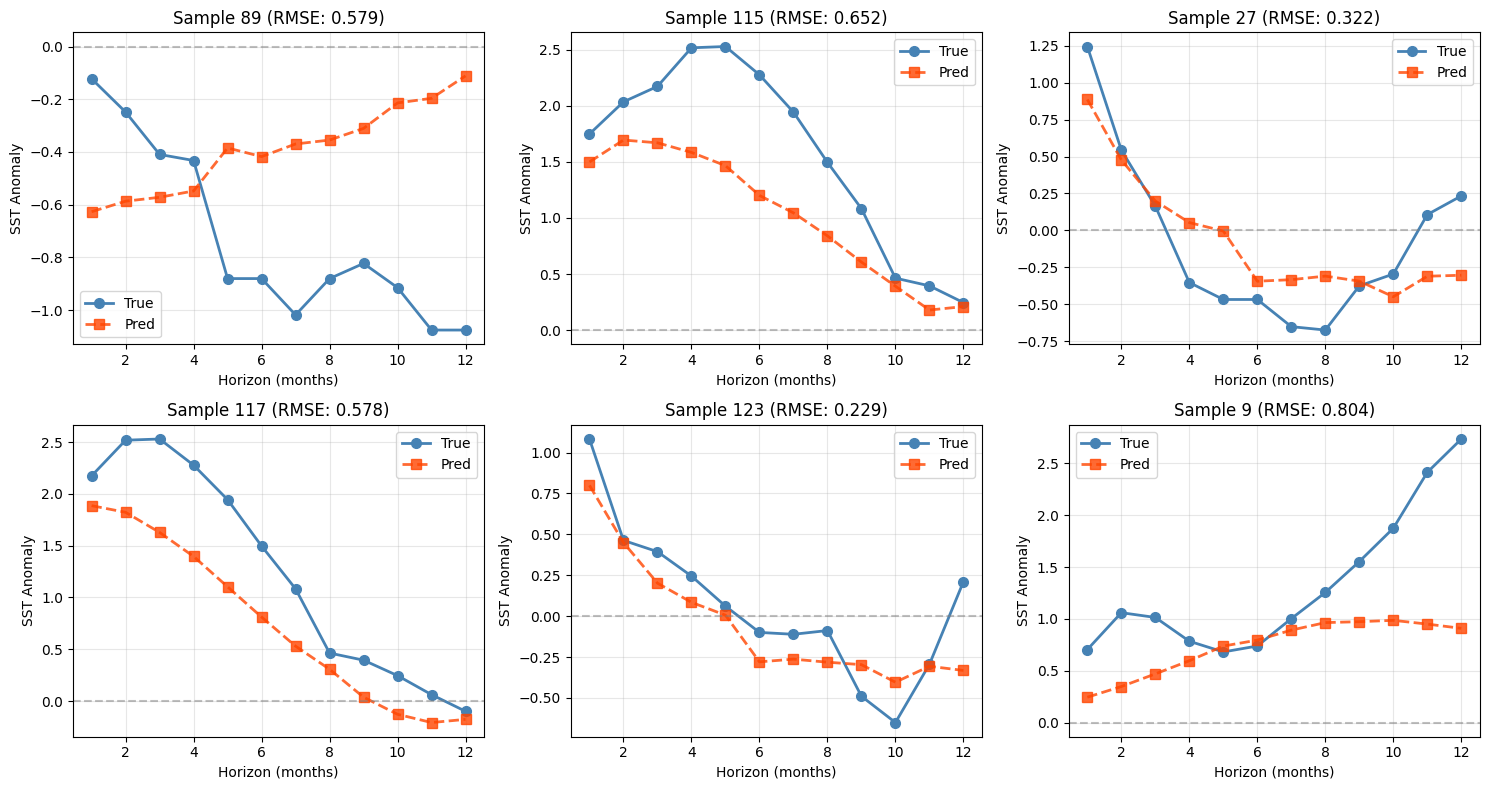


COMPLETED!


In [ ]:
"""
CNN-LSTM for Extended ENSO Dataset
Using Niño 3.4 SST anomaly signal (1950-2025)
"""
import os
import numpy as np
import pandas as pd
import pywt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')


def create_enso_wavelet():
    """Create custom ENSO wavelet"""
    base = pywt.Wavelet('sym6')
    dec_lo = np.array(base.dec_lo)
    dec_hi = np.array(base.dec_hi)
    if sum((-1)**k * dec_hi[k] for k in range(len(dec_hi))) < 0:
        dec_hi = -dec_hi
    rec_lo = dec_lo[::-1]
    rec_hi = dec_hi[::-1]
    return pywt.Wavelet(name="custom_enso", filter_bank=[dec_lo, dec_hi, rec_lo, rec_hi])


class WaveletENSODataset(Dataset):
    """Dataset with rolling wavelet decomposition"""
    
    def __init__(self, signal, custom_wavelet, level=3,
                 lookback=36, forecast_horizon=12, stride=1):  # 36 months = 3 years
        self.lookback = lookback
        self.horizon = forecast_horizon
        self.level = level
        self.custom_wavelet = custom_wavelet
        self.original_signal = np.array(signal).flatten()
        
        print(f"Creating dataset: lookback={lookback} months, horizon={forecast_horizon} months")
        self.X, self.y = self._create_sequences(stride)
        print(f"  Sequences: {len(self.X)}, Input shape: {self.X.shape}")
    
    def _apply_wavelet(self, window):
        coeffs = pywt.wavedec(window, self.custom_wavelet, level=self.level)
        features = []
        for coeff in coeffs:
            upsampled = np.interp(
                np.linspace(0, len(coeff), len(window)),
                np.arange(len(coeff)),
                coeff
            )
            features.append(upsampled)
        return np.array(features).T
    
    def _create_sequences(self, stride):
        X, y = [], []
        max_idx = len(self.original_signal) - self.lookback - self.horizon
        
        for i in range(0, max_idx + 1, stride):
            history = self.original_signal[i:i + self.lookback]
            features = self._apply_wavelet(history)
            future = self.original_signal[i + self.lookback:i + self.lookback + self.horizon]
            X.append(features)
            y.append(future)
        
        return np.array(X), np.array(y)
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return (torch.FloatTensor(self.X[idx]), torch.FloatTensor(self.y[idx]))


class WaveletCNNLSTM(nn.Module):
    """Hybrid CNN-LSTM for ENSO forecasting"""
    
    def __init__(self, n_features=4, forecast_horizon=12):
        super(WaveletCNNLSTM, self).__init__()
        
        self.forecast_horizon = forecast_horizon
        
        # CNN for feature extraction
        self.conv1 = nn.Conv1d(n_features, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(32, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool = nn.MaxPool1d(2)
        self.dropout1 = nn.Dropout(0.3)
        
        # LSTM
        self.lstm = nn.LSTM(
            input_size=32,
            hidden_size=32,
            num_layers=1,
            batch_first=True,
            dropout=0
        )
        
        # Output
        self.dropout2 = nn.Dropout(0.4)
        self.fc = nn.Linear(32, forecast_horizon)
    
    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = torch.relu(self.conv1(x))
        x = self.bn1(x)
        x = torch.relu(self.conv2(x))
        x = self.pool(x)
        x = self.dropout1(x)
        x = x.permute(0, 2, 1)
        
        lstm_out, _ = self.lstm(x)
        last_out = lstm_out[:, -1, :]
        
        x = self.dropout2(last_out)
        output = self.fc(x)
        
        return output


class Trainer:
    """Trainer with proper validation"""
    
    def __init__(self, model, train_loader, val_loader, lr=0.001, device='cpu'):
        self.model = model.to(device)
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.device = device
        
        self.optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
        self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode='min', factor=0.5, patience=15, min_lr=1e-6
        )
        
        self.criterion = nn.MSELoss()
        self.train_losses = []
        self.val_losses = []
        self.best_val_loss = float('inf')
        self.best_model = None
    
    def train_epoch(self):
        self.model.train()
        total_loss = 0
        
        for batch_x, batch_y in self.train_loader:
            batch_x = batch_x.to(self.device)
            batch_y = batch_y.to(self.device)
            
            self.optimizer.zero_grad()
            predictions = self.model(batch_x)
            loss = self.criterion(predictions, batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=0.5)
            self.optimizer.step()
            
            total_loss += loss.item()
        
        return total_loss / len(self.train_loader)
    
    def validate(self):
        self.model.eval()
        total_loss = 0
        
        with torch.no_grad():
            for batch_x, batch_y in self.val_loader:
                batch_x = batch_x.to(self.device)
                batch_y = batch_y.to(self.device)
                predictions = self.model(batch_x)
                loss = self.criterion(predictions, batch_y)
                total_loss += loss.item()
        
        return total_loss / len(self.val_loader)
    
    def train(self, epochs=150, patience=30):
        print(f"\n{'='*70}")
        print("TRAINING CNN-LSTM ON EXTENDED DATASET")
        print(f"{'='*70}")
        print(f"Parameters: {sum(p.numel() for p in self.model.parameters()):,}")
        print(f"{'='*70}\n")
        
        no_improve = 0
        
        for epoch in range(epochs):
            train_loss = self.train_epoch()
            val_loss = self.validate()
            
            self.train_losses.append(train_loss)
            self.val_losses.append(val_loss)
            
            self.scheduler.step(val_loss)
            
            if val_loss < self.best_val_loss:
                self.best_val_loss = val_loss
                self.best_model = self.model.state_dict().copy()
                no_improve = 0
                marker = " ★"
            else:
                no_improve += 1
                marker = ""
            
            if (epoch + 1) % 10 == 0 or epoch == 0:
                lr = self.optimizer.param_groups[0]['lr']
                print(f"Epoch [{epoch+1:3d}/{epochs}] "
                      f"Train: {train_loss:.6f} | Val: {val_loss:.6f} | LR: {lr:.2e}{marker}")
            
            if no_improve >= patience:
                print(f"\nEarly stop at epoch {epoch+1}")
                break
        
        print(f"\nBest val loss: {self.best_val_loss:.6f}")
        if self.best_model:
            self.model.load_state_dict(self.best_model)
        
        return self.train_losses, self.val_losses


class Evaluator:
    """Evaluator with per-horizon metrics and visualization"""
    
    def __init__(self, model, test_loader, device='cpu'):
        self.model = model.to(device)
        self.test_loader = test_loader
        self.device = device
    
    def evaluate(self):
        self.model.eval()
        all_preds, all_targets = [], []
        
        with torch.no_grad():
            for batch_x, batch_y in self.test_loader:
                batch_x = batch_x.to(self.device)
                batch_y = batch_y.to(self.device)
                preds = self.model(batch_x)
                all_preds.append(preds.cpu().numpy())
                all_targets.append(batch_y.cpu().numpy())
        
        predictions = np.concatenate(all_preds, axis=0)
        targets = np.concatenate(all_targets, axis=0)
        
        metrics = {}
        pred_flat = predictions.flatten()
        tgt_flat = targets.flatten()
        
        metrics['RMSE'] = np.sqrt(mean_squared_error(tgt_flat, pred_flat))
        metrics['MAE'] = mean_absolute_error(tgt_flat, pred_flat)
        metrics['R2'] = r2_score(tgt_flat, pred_flat)
        metrics['Corr'] = np.corrcoef(tgt_flat, pred_flat)[0, 1]
        
        # Per-horizon (monthly)
        horizons_to_check = [1, 3, 6, 9, 12]  # 1, 3, 6, 9, 12 months
        for h in horizons_to_check:
            if h <= predictions.shape[1]:
                metrics[f'RMSE_h{h}m'] = np.sqrt(mean_squared_error(targets[:, h-1], predictions[:, h-1]))
                metrics[f'R2_h{h}m'] = r2_score(targets[:, h-1], predictions[:, h-1])
                metrics[f'Corr_h{h}m'] = np.corrcoef(targets[:, h-1], predictions[:, h-1])[0, 1]
        
        # Per-horizon statistics for all horizons
        horizon_metrics = {
            'horizon': [],
            'rmse': [],
            'r2': [],
            'corr': []
        }
        
        for h in range(predictions.shape[1]):
            horizon_metrics['horizon'].append(h + 1)
            horizon_metrics['rmse'].append(np.sqrt(mean_squared_error(targets[:, h], predictions[:, h])))
            horizon_metrics['r2'].append(r2_score(targets[:, h], predictions[:, h]))
            horizon_metrics['corr'].append(np.corrcoef(targets[:, h], predictions[:, h])[0, 1])
        
        metrics['horizon_metrics'] = horizon_metrics
        
        print(f"\n{'='*70}")
        print("EVALUATION RESULTS")
        print(f"{'='*70}")
        print(f"\nOverall Performance:")
        print(f"  RMSE:  {metrics['RMSE']:.6f}")
        print(f"  MAE:   {metrics['MAE']:.6f}")
        print(f"  R²:    {metrics['R2']:.6f}")
        print(f"  Corr:  {metrics['Corr']:.6f}")
        
        print(f"\nPer-Horizon Performance:")
        print(f"{'Horizon':<12} {'RMSE':<12} {'R²':<12} {'Corr':<12}")
        print("-" * 48)
        for h in horizons_to_check:
            if h <= predictions.shape[1]:
                print(f"{h} month(s)    "
                      f"{metrics[f'RMSE_h{h}m']:<12.4f} "
                      f"{metrics[f'R2_h{h}m']:<12.4f} "
                      f"{metrics[f'Corr_h{h}m']:<12.4f}")
        print(f"{'='*70}")
        
        return metrics, predictions, targets
    
    def plot_horizon_skill(self, metrics, save_path='./output/horizon_skill.png'):
        """Plot forecast skill degradation by horizon"""
        
        horizon_data = metrics['horizon_metrics']
        
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        
        # RMSE by horizon
        axes[0].plot(horizon_data['horizon'], horizon_data['rmse'], 'o-', 
                    linewidth=2, markersize=6, color='steelblue')
        axes[0].set_xlabel('Forecast Horizon (months)')
        axes[0].set_ylabel('RMSE')
        axes[0].set_title('RMSE vs Horizon')
        axes[0].grid(True, alpha=0.3)
        
        # R² by horizon
        axes[1].plot(horizon_data['horizon'], horizon_data['r2'], 'o-', 
                    linewidth=2, markersize=6, color='green')
        axes[1].axhline(y=0, color='red', linestyle='--', alpha=0.5)
        axes[1].set_xlabel('Forecast Horizon (months)')
        axes[1].set_ylabel('R²')
        axes[1].set_title('R² vs Horizon')
        axes[1].grid(True, alpha=0.3)
        
        # Correlation by horizon
        axes[2].plot(horizon_data['horizon'], horizon_data['corr'], 'o-', 
                    linewidth=2, markersize=6, color='purple')
        axes[2].axhline(y=0, color='red', linestyle='--', alpha=0.5)
        axes[2].set_xlabel('Forecast Horizon (months)')
        axes[2].set_ylabel('Correlation')
        axes[2].set_title('Correlation vs Horizon')
        axes[2].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()


def main():
    """Main execution with extended dataset"""
    
    print(f"{'='*70}")
    print("CNN-LSTM FOR EXTENDED ENSO DATASET")
    print(f"{'='*70}")
    
    os.makedirs('./output', exist_ok=True)
    
    # Load extended monthly data
    #df = pd.read_csv('./data/enso_extended_monthly.csv', index_col=0, parse_dates=True)
    sst_signal = signal
    
    print(f"\nLoaded data: {len(sst_signal)} monthly observations")
    print(f"Date range: {df.index.min()} to {df.index.max()}")
    print(f"Value range: [{sst_signal.min():.2f}, {sst_signal.max():.2f}]°C")
    
    # Normalize
    sst_mean = np.mean(sst_signal)
    sst_std = np.std(sst_signal)
    sst_norm = (sst_signal - sst_mean) / sst_std
    
    # Create dataset
    custom_wavelet = create_enso_wavelet()
    dataset = WaveletENSODataset(
        signal=sst_norm,
        custom_wavelet=custom_wavelet,
        level=3,
        lookback=36,  # 3 years
        forecast_horizon=12,  # 1 year ahead
        stride=1
    )
    
    # Split: 70% train, 15% val, 15% test
    total = len(dataset)
    train_size = int(0.7 * total)
    val_size = int(0.15 * total)
    
    train_ds = torch.utils.data.Subset(dataset, range(0, train_size))
    val_ds = torch.utils.data.Subset(dataset, range(train_size, train_size + val_size))
    test_ds = torch.utils.data.Subset(dataset, range(train_size + val_size, total))
    
    print(f"\nSplit: Train={len(train_ds)}, Val={len(val_ds)}, Test={len(test_ds)}")
    
    # Loaders
    train_loader = DataLoader(train_ds, batch_size=64, shuffle=False)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)
    
    # Model
    model = WaveletCNNLSTM(n_features=4, forecast_horizon=12)
    
    # Train
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f"Using device: {device}")
    
    trainer = Trainer(model, train_loader, val_loader, lr=0.001, device=device)
    train_losses, val_losses = trainer.train(epochs=150, patience=30)
    
    # Plot training
    plt.figure(figsize=(10, 5))
    plt.plot(train_losses, label='Train', linewidth=2)
    plt.plot(val_losses, label='Val', linewidth=2)
    plt.axhline(y=trainer.best_val_loss, color='r', linestyle='--', alpha=0.7)
    plt.xlabel('Epoch')
    plt.ylabel('MSE Loss')
    plt.title('Training History')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.yscale('log')
    plt.tight_layout()
    plt.savefig('./output/extended_training.png', dpi=300)
    plt.show()
    
    # Evaluate
    evaluator = Evaluator(model, test_loader, device=device)
    metrics, predictions, targets = evaluator.evaluate()
    
    # Plot horizon skill degradation
    evaluator.plot_horizon_skill(metrics, save_path='./output/extended_horizon_skill.png')
    
    # Denormalize
    pred_denorm = predictions * sst_std + sst_mean
    tgt_denorm = targets * sst_std + sst_mean
    
    print(f"\nDenormalized:")
    print(f"  RMSE: {np.sqrt(np.mean((pred_denorm - tgt_denorm)**2)):.4f}°C")
    print(f"  MAE:  {np.mean(np.abs(pred_denorm - tgt_denorm)):.4f}°C")
    
    # Plot sample predictions (6 samples in 2x3 grid)
    n_samples = 6
    indices = np.random.choice(len(predictions), n_samples, replace=False)
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()
    
    for i, idx in enumerate(indices):
        horizon = np.arange(1, predictions.shape[1] + 1)
        
        axes[i].plot(horizon, targets[idx], 'o-', label='True',
                    color='steelblue', linewidth=2, markersize=7)
        axes[i].plot(horizon, predictions[idx], 's--', label='Pred',
                    color='orangered', linewidth=2, markersize=7, alpha=0.8)
        
        rmse = np.sqrt(np.mean((targets[idx] - predictions[idx])**2))
        axes[i].set_title(f'Sample {idx} (RMSE: {rmse:.3f})')
        axes[i].set_xlabel('Horizon (months)')
        axes[i].set_ylabel('SST Anomaly')
        axes[i].legend(loc='best')
        axes[i].grid(True, alpha=0.3)
        axes[i].axhline(y=0, color='gray', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.savefig('./output/extended_predictions_samples.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Save
    torch.save({
        'model_state_dict': model.state_dict(),
        'metrics': metrics,
        'normalization': {'mean': float(sst_mean), 'std': float(sst_std)}
    }, './output/extended_cnn_lstm.pth')
    
    print(f"\n{'='*70}")
    print("COMPLETED!")
    print(f"{'='*70}")
    
    return model, metrics, predictions, targets


if __name__ == "__main__":
    model, metrics, predictions, targets = main()